# Assignment 1 — Mean–variance ETF portfolios
Ten US-listed ETFs span US core/growth/small-cap stocks (SPY/QQQ/IWM), international stocks (EFA/EEM), bonds (AGG/TLT/HYG), gold (GLD), and real estate (VNQ). The genuine Yahoo adjusted-close snapshot was downloaded on 2026-10-08 UTC and covers the fixed five-year study window 2021-10-09 to 2026-10-09 (end exclusive). Source parameters and coverage are in `data/download_meta.json`.

**Run all cells, top to bottom.** Start the kernel in this bundle directory; alternatively the identical Desktop notebook can start in Desktop and uses its relative `etf-portfolio-assignment` subfolder. No repository, configuration file, or user-specific path is needed. Outputs go to the chosen bundle's `results/`. Frozen data is the explicit default; `REFRESH=True` requests Yahoo and raises on failure—there is no offline fallback. Refresh may restate history, so regenerate the report afterward.

Daily logs $r_{it}=\log(P_{it}/P_{i,t-1})$, $\mu=252\bar r$, $\Sigma=252\operatorname{Cov}(r)$ (`ddof=1`). The annualized mean's IID standard error is $252s_{daily}/\sqrt T$ (not annual volatility divided by $\sqrt T$). Serial dependence can invalidate this IID uncertainty measure. The assignment uses $r_f=0.03$ as a **nominal log-model hurdle** for mean–variance/CAL calculations. For exact realized performance the effective annual cash rate is 3%, hence daily cash return $(1.03)^{1/252}-1$.

Weighted logs $w^\top r$ are a **linear model approximation**, not the exact return of a rebalanced portfolio. Exact simple portfolio returns are $w^\top(\exp(r)-1)$; exact portfolio logs, when solvent, are $\log(1+w^\top(\exp(r)-1))$. Model Sharpe and realized simple-excess Sharpe are labeled separately.

In [1]:
import json, time, hashlib
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize
from IPython.display import display

TICKERS = ['SPY','QQQ','IWM','EFA','EEM','AGG','TLT','HYG','GLD','VNQ']
M, RF, CAP, SEED = 252, .03, 3., 42
RF_DAILY = (1+RF)**(1/M)-1
START, END = '2021-10-09', '2026-10-09'  # exclusive end, fixed snapshot study
REFRESH = False  # explicitly opt in to network; failure never uses frozen data
ROOT = Path('.') if Path('data/close_adj.csv').is_file() else Path('etf-portfolio-assignment')
if not (ROOT/'data/close_adj.csv').is_file():
    raise FileNotFoundError('Set kernel cwd to the bundle directory (or Desktop beside its bundle).')
OUT = ROOT/'results'
OUT.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi':110, 'axes.grid':True, 'grid.alpha':.2})
print('Mode:', 'explicit Yahoo refresh' if REFRESH else 'supplied frozen Yahoo snapshot')

Mode: supplied frozen Yahoo snapshot


In [2]:
def validate_prices(panel):
    if list(panel.columns) != TICKERS or len(panel)<2:
        raise ValueError('Incomplete or misordered ticker panel')
    if not isinstance(panel.index,pd.DatetimeIndex) or not panel.index.is_unique or not panel.index.is_monotonic_increasing:
        raise ValueError('Dates must be sorted, unique DatetimeIndex')
    if panel.index.hasnans or not np.isfinite(panel.to_numpy()).all() or (panel.to_numpy()<=0).any():
        raise ValueError('Missing, non-finite or nonpositive prices; no imputation permitted')
    if panel.index.min()<pd.Timestamp(START) or panel.index.max()>=pd.Timestamp(END):
        raise ValueError('Price dates outside fixed study window')
    return panel

def download_prices(retries=3, pause=2.):
    last=None
    for attempt in range(retries):
        try:
            raw=yf.download(TICKERS,start=START,end=END,interval='1d',auto_adjust=False,
                            actions=False,group_by='column',threads=True,progress=False,multi_level_index=True)
            panel=raw['Adj Close'].reindex(columns=TICKERS).copy()
            panel.index=pd.DatetimeIndex(panel.index).tz_localize(None).normalize()
            panel.index.name='date'
            validate_prices(panel)  # retry incomplete/NaN batches, not just empty responses
            if len(panel)<1200 or panel.index.min()>pd.Timestamp(START)+pd.Timedelta(days=7) or panel.index.max()<pd.Timestamp(END)-pd.Timedelta(days=7):
                raise ValueError('Five-year boundary coverage incomplete')
            return panel
        except Exception as exc:
            last=exc
            if attempt+1<retries: time.sleep(pause*2**attempt)
    raise RuntimeError(f'Yahoo refresh failed after {retries} validated batched attempts: {last}')

if REFRESH:
    prices=download_prices()
    prices.to_csv(ROOT/'data/close_adj.csv',float_format='%.6f')
    metadata={'source':'Yahoo Finance via yfinance','generated_utc':datetime.now(timezone.utc).isoformat(),
              'requested_start':START,'requested_end':END,'end_exclusive':True,'interval':'1d',
              'price_field':'Adj Close','auto_adjust':False,'yfinance_version':yf.__version__,
              'panel_start':str(prices.index.min().date()),'panel_end':str(prices.index.max().date()),
              'trading_days':len(prices),'tickers':TICKERS}
    (ROOT/'data/download_meta.json').write_text(json.dumps(metadata,indent=2)+'\n')
else:
    prices=pd.read_csv(ROOT/'data/close_adj.csv',index_col='date',parse_dates=True)
    metadata=json.loads((ROOT/'data/download_meta.json').read_text())
validate_prices(prices)
assert len(prices)>=1200, 'Five-year frozen panel unexpectedly short'
coverage=pd.DataFrame({'first_date':prices.index.min().date(),'last_date':prices.index.max().date(),
                       'observations':prices.count(),'missing':prices.isna().sum()})
coverage.index.name='ticker'
display(coverage)
print('Prices:', prices.shape, 'source:',metadata['source'])

,first_date,last_date,observations,missing
ticker,,,,
SPY,2021-10-11,2026-10-08,1254,0
QQQ,2021-10-11,2026-10-08,1254,0
IWM,2021-10-11,2026-10-08,1254,0
EFA,2021-10-11,2026-10-08,1254,0
EEM,2021-10-11,2026-10-08,1254,0
AGG,2021-10-11,2026-10-08,1254,0
TLT,2021-10-11,2026-10-08,1254,0
HYG,2021-10-11,2026-10-08,1254,0
GLD,2021-10-11,2026-10-08,1254,0


Prices: (1254, 10) source: Yahoo Finance via yfinance


## 1. Estimate the daily log moments
Sample covariance must be symmetric and positive definite before optimization. Annual expected returns below are annualized **mean logs**, not simple expected returns. `exp(mean_annual_log)-1` is a compounded constant-log equivalent, not a fitted lognormal arithmetic expectation.

In [3]:
def estimate(logs):
    x=np.asarray(logs,dtype=float)
    if len(x)<2 or not np.isfinite(x).all():
        raise ValueError('At least two finite return observations required')
    mu,cov=M*x.mean(axis=0),M*np.cov(x,rowvar=False,ddof=1)
    if not np.allclose(cov,cov.T) or np.linalg.eigvalsh(cov).min()<=0:
        raise ValueError('Covariance must be symmetric positive definite')
    return mu,cov,M*x.std(axis=0,ddof=1)/np.sqrt(len(x))

logs=np.log(prices).diff().iloc[1:]
simple=prices.pct_change(fill_method=None).iloc[1:]
mu,S,se=estimate(logs)
vol=np.sqrt(np.diag(S))
assets=pd.DataFrame({'mean_annual_log':mu,'compounded_log_equivalent':np.expm1(mu),
                     'vol_annual_log':vol,'se_mean_annual':se,'sharpe_log_model':(mu-RF)/vol,
                     'realized_total_return':prices.iloc[-1].to_numpy()/prices.iloc[0].to_numpy()-1},index=TICKERS)
assets.index.name='ticker'
corr=pd.DataFrame(S/np.outer(vol,vol),index=TICKERS,columns=TICKERS)
corr.index.name='ticker'
assert np.allclose(np.diff(np.log(prices.to_numpy()),axis=0),logs)
assert np.allclose(np.diag(S),logs.var(ddof=1)*M)
display(assets.round(5))
print('Return observations:',len(logs),'covariance condition number:',np.linalg.cond(S))

,mean_annual_log,compounded_log_equivalent,vol_annual_log,se_mean_annual,sharpe_log_model,realized_total_return
ticker,,,,,,
SPY,0.12910,0.13781,0.17124,0.07679,0.57874,0.90016
QQQ,0.15372,0.16617,0.22946,0.10290,0.53920,1.14759
IWM,0.05812,0.05984,0.22347,0.10022,0.12584,0.33509
EFA,0.08708,0.09099,0.16602,0.07445,0.34382,0.54186
EEM,0.07625,0.07923,0.19976,0.08959,0.23152,0.46101
AGG,-0.00443,-0.00442,0.06140,0.02753,-0.56078,-0.02179
TLT,-0.08450,-0.08103,0.15685,0.07034,-0.72999,-0.34305
HYG,0.03360,0.03417,0.07539,0.03381,0.04777,0.18184
GLD,0.16833,0.18333,0.19001,0.08521,0.72805,1.30942


Return observations: 1253 covariance condition number: 567.6933307801092


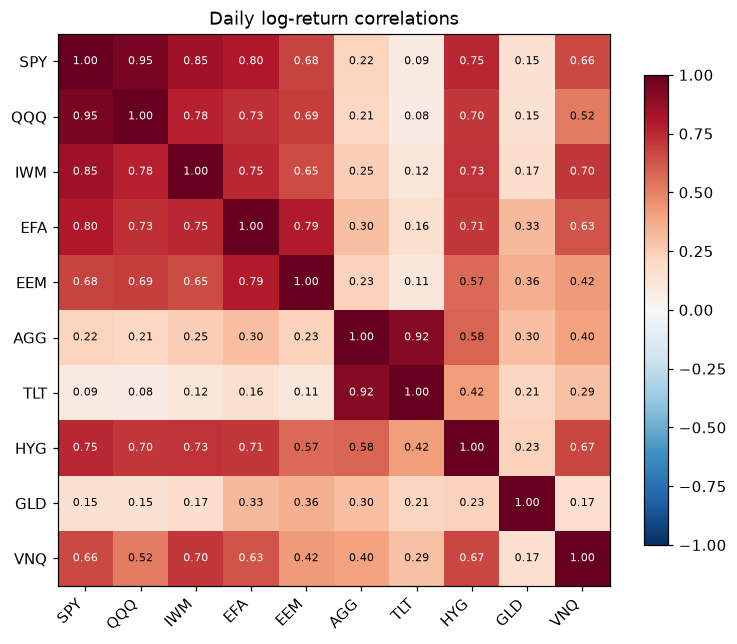

In [4]:
fig,ax=plt.subplots(figsize=(7,6))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(10),TICKERS,rotation=45,ha='right'); ax.set_yticks(range(10),TICKERS)
ax.grid(False)
for i in range(10):
    for j in range(10):
        ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=7,
                color='white' if abs(corr.iloc[i,j])>.6 else 'black')
ax.set_title('Daily log-return correlations'); fig.colorbar(im,ax=ax,shrink=.8)
fig.tight_layout(); fig.savefig(OUT/'correlation.png'); plt.show()

## 2. Mean–variance optimization
For target $q$, minimize $w^\top\Sigma w$ subject to $\mathbf1^\top w=1$, $\mu^\top w=q$; add $w_i\ge0$ for no short sales. Only the upper branch, from each frontier's own MVP, is efficient.

Using linear solves (never explicit inverses), define $A=\mathbf1^\top\Sigma^{-1}\mathbf1$, $B=\mathbf1^\top\Sigma^{-1}\mu$, $C=\mu^\top\Sigma^{-1}\mu$, $\Delta=AC-B^2$. The unrestricted frontier has variance $(Aq^2-2Bq+C)/\Delta$; MVP is $\Sigma^{-1}\mathbf1/A$.

Let $D=B-r_fA$ and $K=(\mu-r_f\mathbf1)^\top\Sigma^{-1}(\mu-r_f\mathbf1)$. If $D>0$, actual **uncapped** tangency is $\Sigma^{-1}(\mu-r_f\mathbf1)/D$ with Sharpe $\sqrt K$. If $D\le0$, there is no finite maximizing fully invested portfolio (for a nondegenerate frontier): the supremum is $\sqrt{C-B^2/A}$, approached as leverage tends to infinity. In particular for $D<0$ it is **not** $\sqrt K$. The optional ±3 solution is explicitly a bounded diagnostic, never a replacement named unrestricted tangency. All numerical solvers must succeed and satisfy equality/bound constraints.

In [5]:
def unrestricted(mu,S):
    one=np.ones(len(mu))
    u,v=np.linalg.solve(S,one),np.linalg.solve(S,mu)
    A,B,C=float(one@u),float(one@v),float(mu@v)
    delta=A*C-B*B
    if delta<=1e-12: raise ValueError('Degenerate frontier: indistinguishable expected means')
    D=B-RF*A
    e=mu-RF*one; z=np.linalg.solve(S,e); K=float(e@z)
    return {'A':A,'B':B,'C':C,'delta':delta,'D':D,'K':K,'u':u,'v':v,
            'mvp':u/A,'tangency':z/D if D>0 else None,
            'supremum':float(np.sqrt(K if D>0 else max(0,C-B*B/A)))}

def frontier_weight(q,info):
    coefficients=np.linalg.solve([[info['A'],info['B']],[info['B'],info['C']]],[1.,q])
    return coefficients[0]*info['u']+coefficients[1]*info['v']

def checked(res,mu,target=None,bounds=None):
    if not res.success: raise RuntimeError(f'Optimizer failed: {res.message}')
    w=np.asarray(res.x)
    if not np.isfinite(w).all() or abs(w.sum()-1)>1e-7 or (target is not None and abs(w@mu-target)>1e-7):
        raise RuntimeError('Optimizer equality constraint violation')
    if bounds is not None and any(wi<lo-1e-7 or wi>hi+1e-7 for wi,(lo,hi) in zip(w,bounds)):
        raise RuntimeError('Optimizer bound violation')
    return w

def constrained(mu,S,target=None,sharpe=False,cap=None):
    n=len(mu); one=np.ones(n)
    bounds=[(0.,1.)]*n if cap is None else [(-cap,cap)]*n
    constraints=[{'type':'eq','fun':lambda w:w.sum()-1,'jac':lambda w:one}]
    if target is not None:
        constraints.append({'type':'eq','fun':lambda w:w@mu-target,'jac':lambda w:mu})
    def objective(w):
        variance=w@S@w
        return -(w@mu-RF)/np.sqrt(variance) if sharpe else variance
    def gradient(w):
        variance=w@S@w; sd=np.sqrt(variance)
        return -mu/sd+(w@mu-RF)*(S@w)/sd**3 if sharpe else 2*S@w
    starts=[one/n]
    if target is not None:
        lo,hi=int(np.argmin(mu)),int(np.argmax(mu))
        a=(target-mu[lo])/(mu[hi]-mu[lo]); x=np.zeros(n); x[lo]=1-a; x[hi]=a
        starts=[x]
    if sharpe: starts += list(np.eye(n))
    solutions=[]
    for x in starts:
        res=minimize(objective,x,jac=gradient,bounds=bounds,constraints=constraints,
                     method='SLSQP',options={'ftol':1e-11,'maxiter':2000})
        solutions.append(checked(res,mu,target,bounds))  # fail any unsuccessful start, no silent filtering
    return min(solutions,key=objective)

def model_stats(w,mu,S):
    r=float(w@mu); s=float(np.sqrt(w@S@w))
    return {'expected_return_log':r,'volatility_log':s,'sharpe_log_model':(r-RF)/s,
            'gross_exposure':float(np.abs(w).sum())}

def portfolios_for(mu,S,include_cap=False):
    info=unrestricted(mu,S)
    weights={'MVP unrestricted':info['mvp'],'MVP long-only':constrained(mu,S),
             'Tangency long-only':constrained(mu,S,sharpe=True),'Equal weight 1/N':np.ones(len(mu))/len(mu)}
    if info['tangency'] is not None: weights['Tangency unrestricted']=info['tangency']
    if include_cap: weights['Bounded Sharpe diagnostic +/-3']=constrained(mu,S,sharpe=True,cap=CAP)
    return weights,info

W,full=portfolios_for(mu,S)
portfolio_table=pd.DataFrame({name:model_stats(w,mu,S) for name,w in W.items()}).T
portfolio_table.index.name='strategy'
weights_full=pd.DataFrame(W,index=TICKERS).T; weights_full.index.name='strategy'
display(portfolio_table.round(5)); display(weights_full.round(4))
print('Full-sample D:',full['D'],'unrestricted maximum attained:',full['tangency'] is not None)

,expected_return_log,volatility_log,sharpe_log_model,gross_exposure
strategy,,,,
MVP unrestricted,0.03308,0.03445,0.08927,2.55367
MVP long-only,0.00570,0.05902,-0.41165,1.00000
Tangency long-only,0.15078,0.13922,0.86753,1.00000
Equal weight 1/N,0.06264,0.12204,0.26746,1.00000
Tangency unrestricted,0.94588,0.59455,1.54045,16.92561


,SPY,QQQ,IWM,EFA,EEM,AGG,TLT,HYG,GLD,VNQ
strategy,,,,,,,,,,
MVP unrestricted,0.2464,-0.1537,-0.0267,-0.0680,0.0284,1.4372,-0.4482,0.0649,-0.0173,-0.0630
MVP long-only,0.0000,0.0000,0.0000,0.0000,0.0000,0.7347,0.0000,0.2650,0.0003,0.0000
Tangency long-only,0.4475,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5525,0.0000
Equal weight 1/N,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000
Tangency unrestricted,6.8331,-1.5630,-1.7175,-0.2245,-0.9038,-0.3668,-1.7810,-0.2263,2.1297,-1.1801


Full-sample D: 2.5909469412230237 unrestricted maximum attained: True


In [6]:
# Efficient branches; unrestricted range includes its actual uncapped tangency.
q0=float(full['mvp']@mu)
qmax=max(float(mu.max()),float(full['tangency']@mu) if full['tangency'] is not None else float(mu.max()))
unrestricted_rows=[]
for q in np.linspace(q0,qmax*1.06 if qmax>0 else qmax+.02,160):
    w=frontier_weight(q,full)
    assert abs(w.sum()-1)<1e-7 and abs(w@mu-q)<1e-7
    assert np.isclose(w@S@w,(full['A']*q*q-2*full['B']*q+full['C'])/full['delta'],atol=1e-9)
    unrestricted_rows.append({'target':q,**model_stats(w,mu,S),**dict(zip(TICKERS,w))})
frontier_unc=pd.DataFrame(unrestricted_rows)
long_rows=[]
for q in np.linspace(float(W['MVP long-only']@mu),float(mu.max()),65):
    w=constrained(mu,S,target=q)
    long_rows.append({'target':q,**model_stats(w,mu,S),**dict(zip(TICKERS,w))})
frontier_long=pd.DataFrame(long_rows)
# Independent unrestricted MVP QP and long-only KKT check.
one=np.ones(len(mu))
res=minimize(lambda w:w@S@w,one/len(mu),jac=lambda w:2*S@w,
             constraints=[{'type':'eq','fun':lambda w:w.sum()-1,'jac':lambda w:one}],
             method='SLSQP',options={'ftol':1e-13,'maxiter':2000})
np.testing.assert_allclose(checked(res,mu),full['mvp'],atol=2e-5)
g=2*S@W['MVP long-only']; active=W['MVP long-only']>1e-5
kkt_residual=float(np.ptp(g[active]))
assert kkt_residual<1e-5 and (g[~active]>=g[active].mean()-1e-5).all()
print('Frontier points:',len(frontier_unc),len(frontier_long),'MVP KKT residual:',kkt_residual)

Frontier points: 160 65 MVP KKT residual: 5.015906068966958e-08


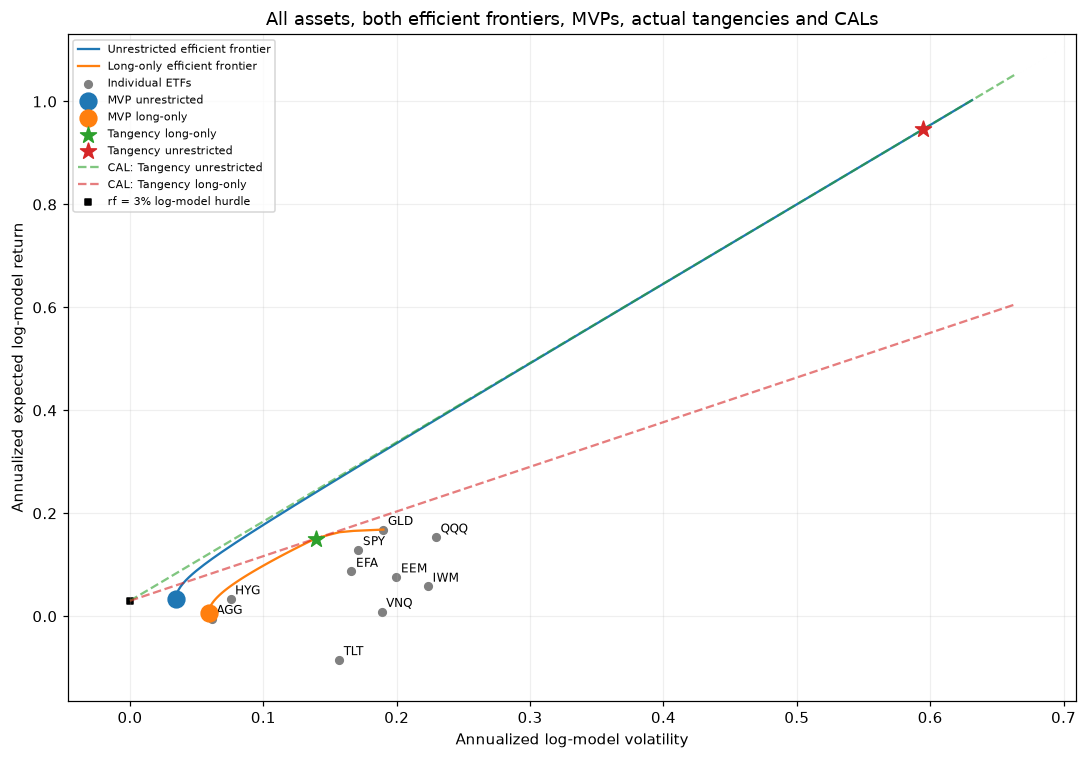

In [7]:
fig,ax=plt.subplots(figsize=(10,7))
ax.plot(frontier_unc.volatility_log,frontier_unc.expected_return_log,label='Unrestricted efficient frontier')
ax.plot(frontier_long.volatility_log,frontier_long.expected_return_log,label='Long-only efficient frontier')
ax.scatter(vol,mu,color='gray',s=25,label='Individual ETFs')
for t,x,y in zip(TICKERS,vol,mu): ax.annotate(t,(x,y),xytext=(3,3),textcoords='offset points',fontsize=8)
for name,row in portfolio_table.iterrows():
    if name=='Equal weight 1/N': continue
    ax.scatter(row.volatility_log,row.expected_return_log,marker='*' if 'Tangency' in name else 'o',s=120,label=name,zorder=5)
xmax=max(float(frontier_unc.volatility_log.max()),float(vol.max()),float(portfolio_table.volatility_log.max()))*1.05
cal_rows=[]
for name in ['Tangency unrestricted','Tangency long-only']:
    if name in W:
        xs=np.linspace(0,xmax,100); ys=RF+portfolio_table.loc[name,'sharpe_log_model']*xs
        ax.plot(xs,ys,'--',alpha=.6,label='CAL: '+name)
        cal_rows += [{'strategy':name,'volatility_log':x,'expected_return_log':y} for x,y in zip(xs,ys)]
cal=pd.DataFrame(cal_rows)
ax.scatter([0],[RF],marker='s',color='black',s=20,label='rf = 3% log-model hurdle')
ax.set_xlabel('Annualized log-model volatility'); ax.set_ylabel('Annualized expected log-model return')
ax.set_title('All assets, both efficient frontiers, MVPs, actual tangencies and CALs')
ax.legend(fontsize=7,loc='best'); ax.margins(.07); fig.tight_layout()
fig.savefig(OUT/'frontier.png'); plt.show()
# Auto limits include every plotted point; no data-specific zoom/clipping.
assert ax.get_xlim()[1]>=xmax and ax.get_ylim()[1]>=max(float(cal.expected_return_log.max()),float(mu.max()))

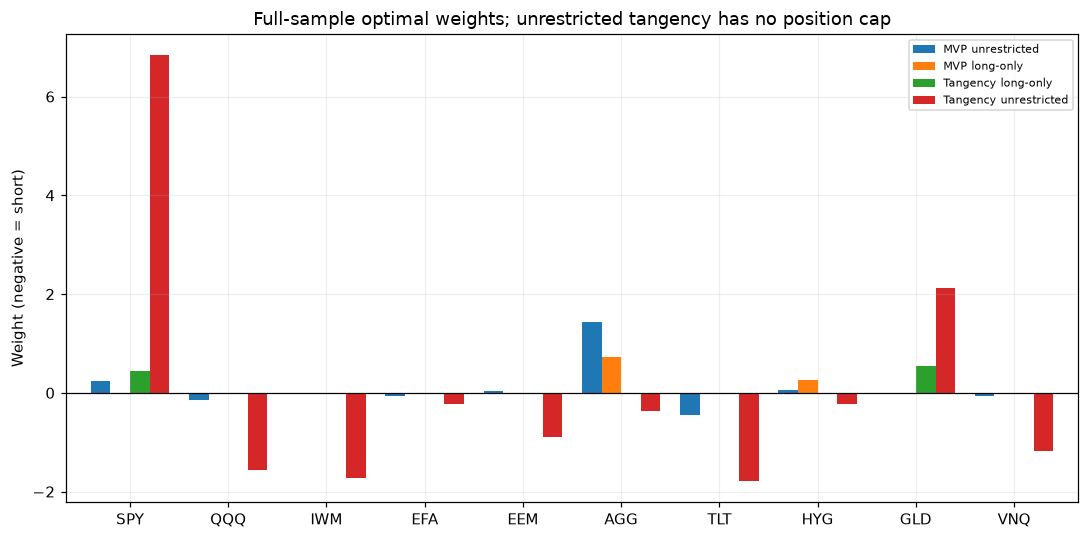

In [8]:
ax=weights_full.drop(index='Equal weight 1/N').T.plot.bar(figsize=(10,5),width=.8)
ax.axhline(0,color='black',lw=.8); ax.set_ylabel('Weight (negative = short)')
ax.set_title('Full-sample optimal weights; unrestricted tangency has no position cap')
ax.tick_params(axis='x',rotation=0); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT/'weights.png'); plt.show()

## 3. Chronological first-three-year / last-two-year holdout
The first trading date on/after the first price date + 3 calendar years is the split base. Training returns end at that date; heldout returns start the next session. The shared boundary price is known before the first heldout return. Weights are fit **only on training returns** and then frozen; 1/N is estimation-free. No ex-post fitted references are used.

The unrestricted tangency is evaluated only if a finite training maximum exists; otherwise its absence and mathematical supremum are reported, and the ±3 bounded diagnostic is labeled separately. Realized Sharpe uses annualized **simple excess** returns, $\sqrt{252}\,\overline{(R_p-r_{f,d})}/s(R_p)$. Daily-rebalanced wealth starts at 1 and follows `cumprod(1+R_p)`. If a day has growth factor ≤0, report insolvency, stop trading and set wealth to zero; CAGR and full-window Sharpe become unavailable. Drawdown includes the initial 1. No fees, short borrowing costs, financing spreads, transaction costs or margin are modeled. The cap alone is not an investability guarantee. One two-year holdout is not statistical proof of robustness.

In [9]:
split_pos=int(prices.index.searchsorted(prices.index[0]+pd.DateOffset(years=3)))
split_date=prices.index[split_pos]
logs_is,logs_oos=logs.iloc[:split_pos],logs.iloc[split_pos:]
simple_is,simple_oos=simple.iloc[:split_pos],simple.iloc[split_pos:]
assert len(logs_is)+len(logs_oos)==len(prices)-1
assert logs_is.index.max()<logs_oos.index.min()
mu_is,S_is,se_is=estimate(logs_is)
W_is,training=portfolios_for(mu_is,S_is,include_cap=True)
weights_is=pd.DataFrame(W_is,index=TICKERS).T; weights_is.index.name='strategy'
print('Split:',split_date.date(),'IS / OOS returns:',len(logs_is),len(logs_oos))
print('Training D:',training['D'],'finite unrestricted tangency:',training['tangency'] is not None,
      'unrestricted Sharpe supremum:',training['supremum'])
display(weights_is.round(4))
# Independent raw-price reconstruction proves training-only MVP computation.
is_prices=prices.iloc[:split_pos+1].to_numpy()
is_raw=np.diff(np.log(is_prices),axis=0)
S_check=M*((is_raw-is_raw.mean(0)).T@(is_raw-is_raw.mean(0)))/(len(is_raw)-1)
u=np.linalg.solve(S_check,np.ones(10))
np.testing.assert_allclose(W_is['MVP unrestricted'],u/u.sum(),atol=1e-10)

Split: 2024-10-11 IS / OOS returns: 755 498
Training D: -2.474649860907725 finite unrestricted tangency: False unrestricted Sharpe supremum: 1.901081887041859


,SPY,QQQ,IWM,EFA,EEM,AGG,TLT,HYG,GLD,VNQ
strategy,,,,,,,,,,
MVP unrestricted,0.3041,-0.1846,-0.0203,-0.0805,0.0452,1.4906,-0.4499,0.0124,-0.0384,-0.0787
MVP long-only,0.0000,0.0000,0.0000,0.0000,0.0064,0.7555,0.0000,0.2127,0.0254,0.0000
Tangency long-only,0.2946,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.7054,0.0000
Equal weight 1/N,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000
Bounded Sharpe diagnostic +/-3,3.0000,-0.7770,-0.7339,-0.2689,-0.8026,-0.5853,-0.6893,0.8206,1.4513,-0.4149


In [10]:
def performance(simple,w):
    r=np.asarray(simple)@w
    if len(r)<2 or not np.isfinite(r).all(): raise ValueError('Invalid realized returns')
    factors=1+r
    bad=np.flatnonzero(factors<=0)
    insolvent=bool(len(bad))
    wealth=np.ones(len(r)+1)
    if insolvent:
        k=int(bad[0]); wealth[1:k+1]=np.cumprod(factors[:k]); wealth[k+1:]=0.
    else: wealth[1:]=np.cumprod(factors)
    sd=float(r.std(ddof=1))
    result={'mean_annual_simple':None if insolvent else float(M*r.mean()),
            'volatility_simple':None if insolvent else float(np.sqrt(M)*sd),
            'sharpe_simple':None if insolvent or sd==0 else float(np.sqrt(M)*(r-RF_DAILY).mean()/sd),
            'total_return':float(wealth[-1]-1),
            'cagr':None if insolvent else float(wealth[-1]**(M/len(r))-1),
            'max_drawdown':float((wealth/np.maximum.accumulate(wealth)-1).min()),
            'insolvent':insolvent,'first_insolvent_return_position':int(bad[0]) if insolvent else None}
    return result,wealth

rows=[]; curves={}
for name,w in W_is.items():
    assert abs(w.sum()-1)<1e-7
    for period,data in [('IS',simple_is),('OOS',simple_oos)]:
        stats,wealth=performance(data,w)
        rows.append({'strategy':name,'period':period,**stats})
        if period=='OOS': curves[name]=wealth
performance_table=pd.DataFrame(rows)
wealth_oos=pd.DataFrame(curves,index=prices.index[split_pos:]); wealth_oos.index.name='date'
assert np.allclose(wealth_oos.iloc[0],1)
sharpe_comparison=performance_table.pivot(index='strategy',columns='period',values='sharpe_simple').reindex(W_is)
benchmark=sharpe_comparison.loc['Equal weight 1/N','OOS']
sharpe_comparison['OOS_minus_1N']=sharpe_comparison['OOS']-benchmark
display(performance_table.round(5)); display(sharpe_comparison.round(4))

,strategy,period,mean_annual_simple,volatility_simple,sharpe_simple,total_return,cagr,max_drawdown,insolvent,first_insolvent_return_position
0,MVP unrestricted,IS,0.01917,0.03949,-0.26304,0.05666,0.01856,-0.07345,False,None
1,MVP unrestricted,OOS,0.03357,0.02609,0.15368,0.06787,0.03379,-0.01728,False,None
2,MVP long-only,IS,-0.00016,0.06806,-0.43665,-0.00737,-0.00247,-0.16524,False,None
3,MVP long-only,OOS,0.02838,0.04302,-0.02750,0.05575,0.02783,-0.04149,False,None
4,Tangency long-only,IS,0.13936,0.11969,0.91736,0.48586,0.14131,-0.17987,False,None
5,Tangency long-only,OOS,0.22612,0.18678,1.05237,0.51002,0.23188,-0.17499,False,None
6,Equal weight 1/N,IS,0.04886,0.12604,0.15315,0.13047,0.04178,-0.24636,False,None
7,Equal weight 1/N,OOS,0.12194,0.11602,0.79623,0.25568,0.12211,-0.10543,False,None
8,Bounded Sharpe diagnostic +/-3,IS,0.50510,0.26465,1.79688,3.08479,0.59953,-0.20022,False,None
9,Bounded Sharpe diagnostic +/-3,OOS,0.40833,0.35734,1.05998,0.97372,0.41066,-0.46318,False,None


period,IS,OOS,OOS_minus_1N
strategy,,,
MVP unrestricted,-0.2630,0.1537,-0.6425
MVP long-only,-0.4366,-0.0275,-0.8237
Tangency long-only,0.9174,1.0524,0.2561
Equal weight 1/N,0.1532,0.7962,0.0000
Bounded Sharpe diagnostic +/-3,1.7969,1.0600,0.2637


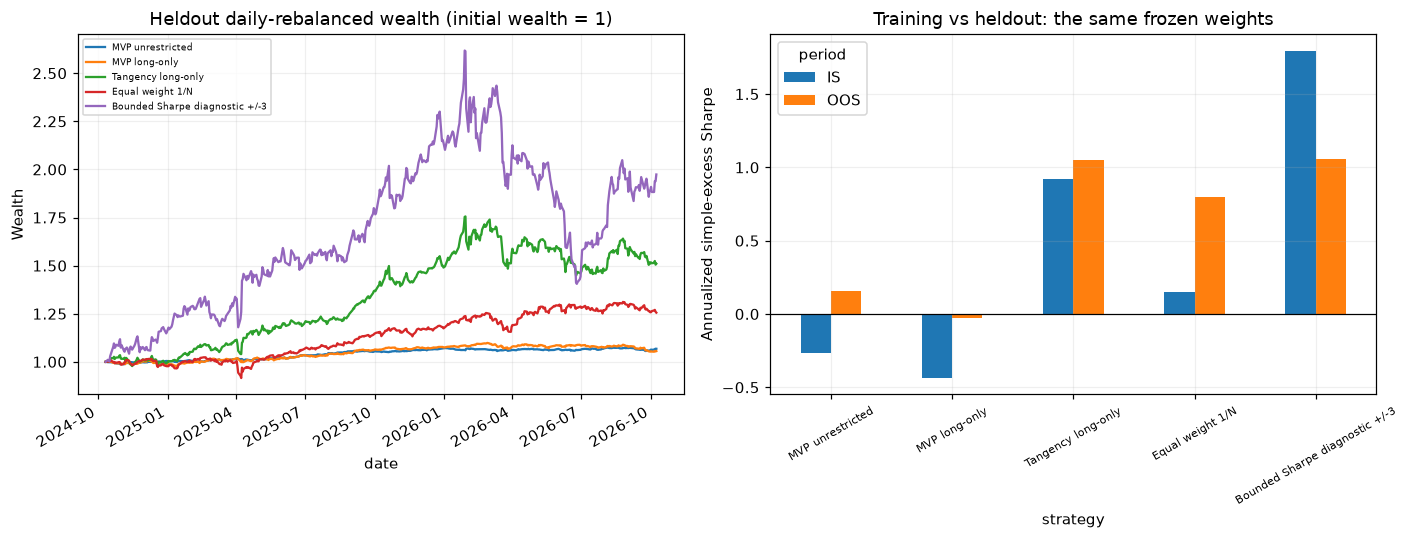

In [11]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
wealth_oos.plot(ax=axes[0],lw=1.5)
axes[0].set_title('Heldout daily-rebalanced wealth (initial wealth = 1)')
axes[0].set_ylabel('Wealth'); axes[0].legend(fontsize=6)
sharpe_comparison[['IS','OOS']].plot.bar(ax=axes[1])
axes[1].axhline(0,color='black',lw=.8); axes[1].set_ylabel('Annualized simple-excess Sharpe')
axes[1].set_title('Training vs heldout: the same frozen weights')
axes[1].tick_params(axis='x',labelsize=7,rotation=30)
fig.tight_layout(); fig.savefig(OUT/'oos.png'); plt.show()

## 4. Report inputs and limitations
All numeric tables/plot coordinates below are exported at full precision for the separate 2–3 page report. Log-model expected returns are not forecasts of exact realized simple returns. Sample means and unrestricted leverage are sensitive to estimation error; the one chronological holdout diagnoses this, not a universal ranking. Costs and changing exposures would further affect realized returns. The frozen snapshot makes this particular assignment reproducible, not a promise that today's Yahoo-adjusted history remains unchanged.

In [12]:
tables={'assets':assets,'cov_annual':pd.DataFrame(S,index=pd.Index(TICKERS,name='ticker'),columns=TICKERS),
        'correlation':corr,'log_returns_daily':logs,'full_portfolios':portfolio_table,
        'full_weights':weights_full,'frontier_unrestricted':frontier_unc,'frontier_long_only':frontier_long,
        'cal':cal,'is_weights':weights_is,'performance':performance_table,
        'oos_wealth':wealth_oos,'sharpe_comparison':sharpe_comparison,'coverage':coverage}
for name,table in tables.items():
    table.to_csv(OUT/(name+'.csv'),index=name not in ['frontier_unrestricted','frontier_long_only','cal','performance'],float_format='%.12g')

def info_json(info):
    return {k:float(info[k]) for k in ['A','B','C','delta','D','K','supremum']} | {
        'tangency_attained':info['tangency'] is not None,
        'status':'finite uncapped maximum' if info['tangency'] is not None else 'no finite maximum; infinite-leverage supremum'}

summary={'schema_version':1,'source':metadata,
         'data':{'price_rows':len(prices),'return_rows':len(logs),'tickers':TICKERS,
                 'first_date':str(prices.index[0].date()),'last_date':str(prices.index[-1].date()),
                 'csv_sha256':hashlib.sha256((ROOT/'data/close_adj.csv').read_bytes()).hexdigest()},
         'conventions':{'annualization':M,'ddof':1,'rf_log_model':RF,'rf_effective_annual':RF,
                        'rf_daily_simple':RF_DAILY,'mean_SE':'252 * daily sample std / sqrt(T)',
                        'model_return':'linear weighted daily logs, an approximation',
                        'performance_return':'exact weighted daily simple returns, daily rebalanced',
                        'performance_sharpe':'sqrt(252) * mean(simple return - daily rf) / sample std(simple return)'},
         'full_sample':{'diagnostic':info_json(full),'portfolios':portfolio_table.to_dict('index'),
                        'weights':weights_full.to_dict('index'),'mvp_kkt_residual':kkt_residual},
         'holdout':{'split_base_date':str(split_date.date()),'first_oos_return_date':str(logs_oos.index[0].date()),
                    'n_is':len(logs_is),'n_oos':len(logs_oos),'training_diagnostic':info_json(training),
                    'weights':weights_is.to_dict('index'),'performance':performance_table.to_dict('records')},
         'files':{name:name+'.csv' for name in tables},
         'limitations':['One holdout window; uncertain sample means','No fees, financing, borrow costs or margin',
                        'IID mean standard errors omit serial dependence','Yahoo adjusted history may be revised']}
# Convert nonfinite optional metrics to JSON null (strict JSON, no NaN).
def json_safe(value):
    if isinstance(value,dict): return {k:json_safe(v) for k,v in value.items()}
    if isinstance(value,list): return [json_safe(v) for v in value]
    if isinstance(value,float) and not np.isfinite(value): return None
    return value
summary=json_safe(summary)
(OUT/'summary.json').write_text(json.dumps(summary,indent=2,allow_nan=False)+'\n')
print('Saved',len(tables),'CSV tables and summary.json in',OUT)
print('OOS simple-excess Sharpes:',sharpe_comparison.OOS.to_dict())

Saved 14 CSV tables and summary.json in results
OOS simple-excess Sharpes: {'MVP unrestricted': 0.15368315069690933, 'MVP long-only': -0.02749580056192901, 'Tangency long-only': 1.0523688785506011, 'Equal weight 1/N': 0.7962314320637218, 'Bounded Sharpe diagnostic +/-3': 1.059975480369366}
